   Experience  Salary
0           1   25000
1           2   30000
2           3   36000
3           4   42000
4           5   50000
5           6   60000
6           7   72000
7           8   85000
8           9   98000
9          10  115000


Enter The Experience:  15


[94868.60802002 41308.44450168]

Model Performance
------------------------------
MAE : 7219.918240830295
MSE : 68843266.38994718
RMSE: 8297.184244666812
R2 Score: 0.9404470013927793

Prediction Comparison
   Actual     Predicted
0   98000  94868.608020
1   30000  41308.444502


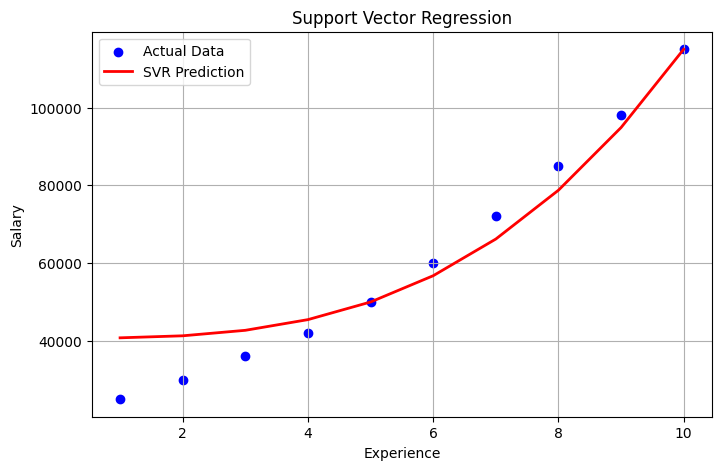

In [3]:
# ==========================
# Import Libraries
# ==========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Warning Ignore
import warnings
warnings.filterwarnings("ignore")

# Feature Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import MaxAbsScaler

from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.DataFrame({
    "Experience": [1,2,3,4,5,6,7,8,9,10],
    "Salary": [25000,30000,36000,42000,50000,
               60000,72000,85000,98000,115000]
})

print(df)


X = df[["Experience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = SVR(
    kernel="poly",
    C=100,
    epsilon=0.1,
    gamma="scale"
)


model.fit(X_train, y_train)

y_pred = int(input("Enter The Experience: "))
y_pred = model.predict(X_test)
print(y_pred)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Performance")
print("-" * 30)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nPrediction Comparison")
print(result)


plt.figure(figsize=(8,5))

plt.scatter(
    X,
    y,
    color="blue",
    label="Actual Data"
)

plt.plot(
    X,
    model.predict(X),
    color="red",
    linewidth=2,
    label="SVR Prediction"
)

plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Support Vector Regression")

plt.legend()
plt.grid(True)

plt.show()

MAE : 3414.399904240967
MSE : 18498081.23312045
RMSE : 4300.939575618385
R2 Score : 0.9839981996253283
   Actual      Predicted
0   98000  104029.730577
1   30000   29200.930768


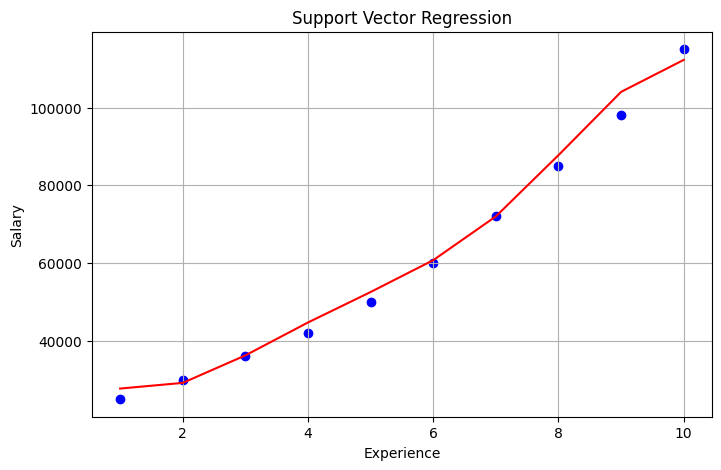

Enter Experience :  18


Predicted Salary : 65277.51303993625


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.DataFrame({
    "Experience":[1,2,3,4,5,6,7,8,9,10],
    "Salary":[25000,30000,36000,42000,50000,60000,72000,85000,98000,115000]
})

X = df[["Experience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = X_scaler.fit_transform(X_train)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(result)

X_plot = X_scaler.transform(X)

y_plot = model.predict(X_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()

plt.figure(figsize=(8,5))
plt.scatter(X, y, color="blue")
plt.plot(X, y_plot, color="red")
plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Support Vector Regression")
plt.grid(True)
plt.show()

exp = float(input("Enter Experience : "))

new_data = [[exp]]

new_data = X_scaler.transform(new_data)

prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print("Predicted Salary :", prediction[0][0])

    Experience  Age  Projects  Salary
0            1   22         1   25000
1            2   23         2   30000
2            3   24         2   36000
3            4   25         3   43000
4            5   27         3   52000
5            6   29         4   62000
6            7   31         5   74000
7            8   33         5   88000
8            9   35         6  103000
9           10   37         7  120000
10          11   39         8  138000
11          12   41         9  158000
MAE Is: 8331.293985671235
MSE Is: 105057188.0228579
RMSE Is: 10249.74087588842
R2 Score Is:  0.957251347671321
   Actual      Predicted
0  138000  144329.105534
1  120000  122228.619924
2   25000   41436.156498


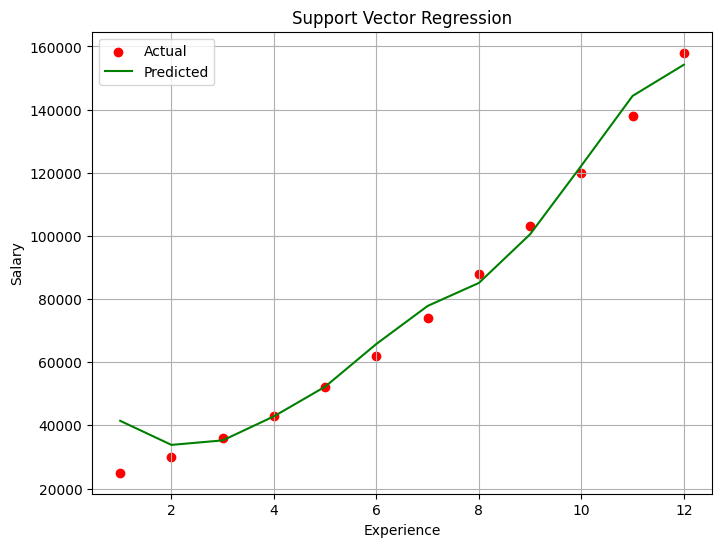

Enter The Experience:  15
Enter The Age:  35
Enter The Projects:  24


Predicted Salary:  90015.89321744922


In [13]:
import pandas as pd

df = pd.DataFrame({
    "Experience":[1,2,3,4,5,6,7,8,9,10,11,12],
    "Age":[22,23,24,25,27,29,31,33,35,37,39,41],
    "Projects":[1,2,2,3,3,4,5,5,6,7,8,9],
    "Salary":[25000,30000,36000,43000,52000,62000,74000,88000,103000,120000,138000,158000]
})

print(df)

x = df[["Experience","Age","Projects"]]
y = df["Salary"]


x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()


x_train = x_scaler.fit_transform(x_train)
x_test = x_scaler.transform(x_test)


y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(x_train,y_train)
y_pred = model.predict(x_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()


mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)


print(f"MAE Is: {mae}")
print(f"MSE Is: {mse}")
print(f"RMSE Is: {rmse}")
print(f"R2 Score Is:  {r2}")



result = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_pred
})

print(result)


x_plot = x_scaler.transform(x)
y_plot_scaled = model.predict(x_plot)
y_plot = y_scaler.inverse_transform(y_plot_scaled.reshape(-1,1)).ravel()

plt.figure(figsize=(8,6))
plt.scatter(df["Experience"], df["Salary"], color="red", label="Actual")
plt.plot(df["Experience"], y_plot, color="green", label="Predicted")
plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Support Vector Regression")
plt.legend()
plt.grid(True)
plt.show()


exp = float(input("Enter The Experience: "))
age = float(input("Enter The Age: "))
pro = float(input("Enter The Projects: "))

new_data = [[exp,age,pro]]

new_data = x_scaler.transform(new_data)

prediction = model.predict(new_data)


prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print(f"Predicted Salary:  {prediction[0][0]}")

    Area  Bedrooms  Bathrooms  House_Age  Price
0    600         1          1         20     18
1    800         2          1         18     24
2   1000         2          2         16     31
3   1200         3          2         15     40
4   1400         3          2         13     49
5   1600         3          3         10     60
6   1800         4          3          8     72
7   2000         4          3          6     86
8   2200         5          4          5    101
9   2500         5          4          4    118
10  2800         5          5          3    135
11  3000         6          5          2    150
MSE:  158.57022705461424
MAE: 8.5567006563408
RMSE:  12.592467075780434
R2 Score:  0.9404816063269861
   Actual  Prediction
0     135  133.311346
1     118  115.634872
2      18   39.616320


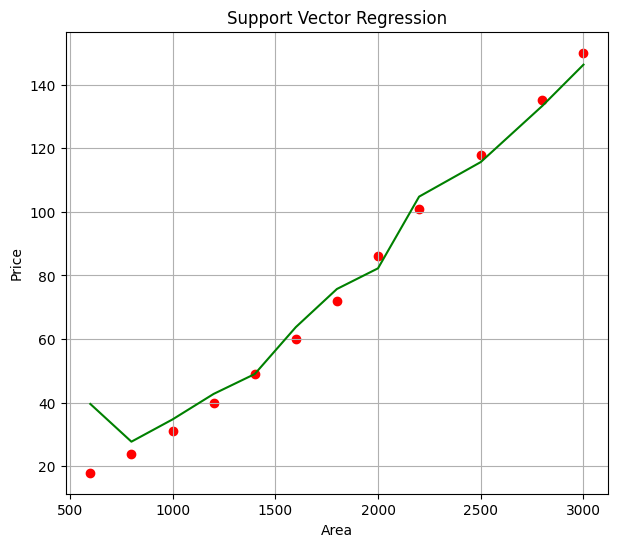

Enter The Area:  1900
Enter The Bedrooms:  3
Enter The Bathrooms:  3
Enter The House Age:  2


Predicted Price:  82.14000380765611


In [16]:
import pandas as pd

df = pd.DataFrame({
    "Area":[600,800,1000,1200,1400,1600,1800,2000,2200,2500,2800,3000],
    "Bedrooms":[1,2,2,3,3,3,4,4,5,5,5,6],
    "Bathrooms":[1,1,2,2,2,3,3,3,4,4,5,5],
    "House_Age":[20,18,16,15,13,10,8,6,5,4,3,2],
    "Price":[18,24,31,40,49,60,72,86,101,118,135,150]
})

print(df)

x = df[["Area","Bedrooms","Bathrooms","House_Age"]]
y = df["Price"]


x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)


x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_train = x_scaler.fit_transform(x_train)
x_test = x_scaler.transform(x_test)

y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()


model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)


model.fit(x_train,y_train)

y_pred = model.predict(x_test)


y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()


mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)


print(f"MSE:  {mse}")
print(f"MAE: {mae}")
print(f"RMSE:  {rmse}")
print(f"R2 Score:  {r2}")


result = pd.DataFrame({
    "Actual":y_test.values,
    "Prediction":y_pred
})

print(result)


x_plot = x_scaler.transform(x)
y_plot = model.predict(x_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()


plt.figure(figsize=(7,6))
plt.scatter(df["Area"], df["Price"],color="red")
plt.plot(df["Area"], y_plot, color="green", label="Predicted")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Support Vector Regression")
plt.grid(True)
plt.show()


area = float(input("Enter The Area: "))
bed = float(input("Enter The Bedrooms: "))
bath = float(input("Enter The Bathrooms: "))
age = float(input("Enter The House Age: "))

new_data = [[age,area,bed,bath]]

new_data = x_scaler.transform(new_data)

prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print("Predicted Price: ",prediction[0][0])

    Car_Age  Mileage  Engine_CC  Price
0        10   150000       1000    2.5
1         9   140000       1000    3.1
2         8   128000       1200    4.0
3         7   112000       1200    5.0
4         6    98000       1500    6.3
5         5    82000       1500    7.8
6         4    68000       1500    9.4
7         3    52000       1800   11.3
8         2    36000       1800   13.8
9         1    22000       2000   16.2
10        1    15000       2000   18.0
11        0     5000       2200   21.0
MAE:  0.8594302780597515
MSE:  0.8594302780597515
RMSE: 0.9270546251757507
R2 Score: 0.9812247642377552
   Actual  Predicted
0    18.0  17.668165
1    16.2  14.896348
2     2.5   3.442804


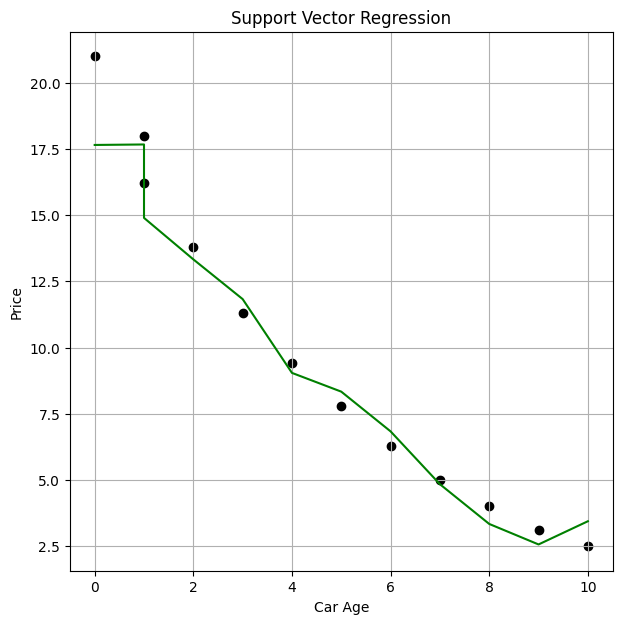

Enter The Car Age:  5
Enter The Mileage:  10
Enter The Engine CC:   2200


Predicted Price Is:  43.80335489736733


In [21]:
import pandas as pd

df = pd.DataFrame({
    "Car_Age":[10,9,8,7,6,5,4,3,2,1,1,0],
    "Mileage":[150000,140000,128000,112000,98000,82000,68000,52000,36000,22000,15000,5000],
    "Engine_CC":[1000,1000,1200,1200,1500,1500,1500,1800,1800,2000,2000,2200],
    "Price":[2.5,3.1,4.0,5.0,6.3,7.8,9.4,11.3,13.8,16.2,18.0,21.0]
})

print(df)

x = df[["Car_Age","Mileage","Engine_CC"]]
y = df["Price"]

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_train = x_scaler.fit_transform(x_train)
x_test = x_scaler.transform(x_test)


y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()


model = SVR(
    kernel="linear",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()


mae = mean_absolute_error(y_test,y_pred)
mse = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)


print(f"MAE:  {mae}")
print(f"MSE:  {mse}")
print(f"RMSE: {rmse}")
print(f"R2 Score: {r2}")


result = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_pred
})

print(result)


x_plot = x_scaler.transform(x)
y_plot = model.predict(x_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()


plt.figure(figsize=(7,7))
plt.scatter(df["Car_Age"],df["Price"],color="black")
plt.plot(df["Car_Age"], y_plot, color="green", label="Predicted")
plt.xlabel("Car Age")
plt.ylabel("Price")
plt.title("Support Vector Regression")
plt.grid(True)
plt.show()



car_age = float(input("Enter The Car Age: "))
Mil = float(input("Enter The Mileage: "))
cc = float(input("Enter The Engine CC:  "))

new_data = [[car_age,Mil,cc]]

new_data = x_scaler.transform(new_data)
prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print(f"Predicted Price Is:  {prediction[0][0]}")

    Study_Hours  Attendance  Assignments  Marks
0             1          55            2     35
1             2          60            3     40
2             3          65            4     47
3             4          70            5     56
4             5          75            6     66
5             6          80            7     76
6             7          85            8     84
7             8          90            9     90
8             9          92           10     94
9            10          95           11     97
10           11          98           12     99
11           12         100           12    100
MAE:   1.8521126364585119
MSE:   4.62366734351012
RMSE:  2.150271458097819
R2 Score:  0.9947617061818239
   Actual   predicted
0      99  101.660263
1      97   97.307779
2      35   32.411704


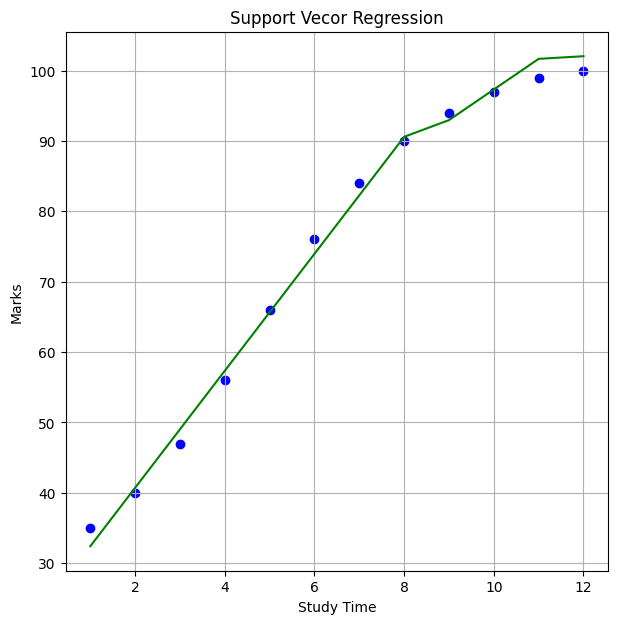

Enter The Study Time:  9
Enter The Attendence:  76
Enter The Assignments:  8


Predicted Marks:  57.2906454176175


In [26]:
import pandas as pd

df = pd.DataFrame({
    "Study_Hours":[1,2,3,4,5,6,7,8,9,10,11,12],
    "Attendance":[55,60,65,70,75,80,85,90,92,95,98,100],
    "Assignments":[2,3,4,5,6,7,8,9,10,11,12,12],
    "Marks":[35,40,47,56,66,76,84,90,94,97,99,100]
})

print(df)

x = df[["Study_Hours","Attendance","Assignments"]]
y = df["Marks"]

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_train = x_scaler.fit_transform(x_train)
x_test = x_scaler.transform(x_test)

y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()


model = SVR(
    kernel="linear",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()


mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print(f"MAE:   {mae}")
print(f"MSE:   {mse}")
print(f"RMSE:  {rmse}")
print(f"R2 Score:  {r2}")


result = pd.DataFrame({
    "Actual":y_test.values,
    "predicted":y_pred
})

print(result)


x_plot = x_scaler.transform(x)
y_plot = model.predict(x_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()


plt.figure(figsize=(7,7))
plt.scatter(df["Study_Hours"],df["Marks"],color="blue")
plt.plot(df["Study_Hours"], y_plot, color="green", label="Predicted")
plt.xlabel("Study Time")
plt.ylabel("Marks")
plt.title("Support Vecor Regression")
plt.grid(True)
plt.show()


std_time = float(input("Enter The Study Time: "))
att = float(input("Enter The Attendence: "))
assing = float(input("Enter The Assignments: "))


new_data = [[std_time,att,assing]]

new_data = x_scaler.transform(new_data)

prediction = model.predict(new_data)

prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print(f"Predicted Marks:  {prediction[0][0]}")

    Age  BMI  Smoker  Exercise_Hours  Insurance_Cost
0    20   19       0               8            2000
1    25   21       0               7            2500
2    30   23       0               6            3200
3    35   24       1               5            5000
4    40   26       0               5            4800
5    45   28       1               4            7000
6    50   30       1               3            8500
7    55   31       1               3            9800
8    60   33       1               2           11500
9    65   35       1               2           13500
10   70   36       1               1           15500
11   75   38       1               1           18000
MAE:  841.0598288185425
MSE:  1270510.6124067102
RMSE:  1127.1692918132173
R2 Score:  0.9640986012192766
   Actual    Prediction
0   15500  13660.437004
1   13500  13530.461117
2    2000   1346.844627


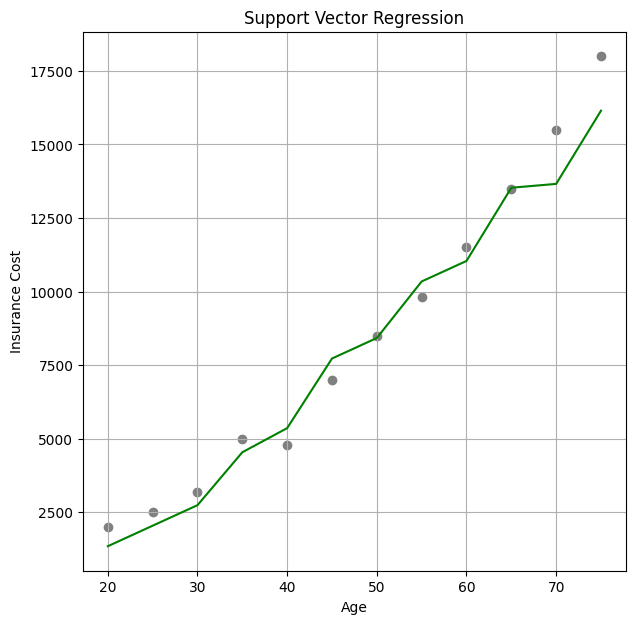

Enter The Age:  21
Enter The BMI:  25
Enter The Smoke:  1
Enter The Workout Time:  2


Predicted Insurance Cost Is:  -4057.936244679673


In [33]:
import pandas as pd

df = pd.DataFrame({
    "Age":[20,25,30,35,40,45,50,55,60,65,70,75],
    "BMI":[19,21,23,24,26,28,30,31,33,35,36,38],
    "Smoker":[0,0,0,1,0,1,1,1,1,1,1,1],
    "Exercise_Hours":[8,7,6,5,5,4,3,3,2,2,1,1],
    "Insurance_Cost":[2000,2500,3200,5000,4800,7000,8500,9800,11500,13500,15500,18000]
})

print(df)

x = df[["Age","BMI","Smoker","Exercise_Hours"]]
y = df["Insurance_Cost"]

x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_train = x_scaler.fit_transform(x_train)
x_test = x_scaler.transform(x_test)

y_train = y_scaler.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

model = SVR(
    kernel="linear",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

y_pred = y_scaler.inverse_transform(
    y_pred.reshape(-1,1)
).ravel()


mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)


print(f"MAE:  {mae}")
print(f"MSE:  {mse}")
print(f"RMSE:  {rmse}")
print(f"R2 Score:  {r2}")


result = pd.DataFrame({
    "Actual":y_test.values,
    "Prediction":y_pred
})

print(result)

x_plot = x_scaler.transform(x)
y_plot = model.predict(x_plot)

y_plot = y_scaler.inverse_transform(
    y_plot.reshape(-1,1)
).ravel()


plt.figure(figsize=(7,7))
plt.scatter(df["Age"],df["Insurance_Cost"],color="gray")
plt.plot(df["Age"], y_plot, color="green", label="Predicted")
plt.xlabel("Age")
plt.ylabel("Insurance Cost")
plt.title("Support Vector Regression")
plt.grid(True)
plt.show()


age = float(input("Enter The Age: "))
bmi = float(input("Enter The BMI: "))
smk = float(input("Enter The Smoke: "))
exh = float(input("Enter The Workout Time: "))


new_data = [[age,bmi,smk,exh]]

new_data = x_scaler.transform(new_data)

prediction = model.predict(new_data)

prediction = y_scaler.inverse_transform(
    prediction.reshape(-1,1)
)

print(f"Predicted Insurance Cost Is:  {prediction[0][0]}")